# Previsões Táticas e Pré-táticas de Atrasos de Voo
Este notebook integra análise de dados, seleção de features, balanceamento e treinamento de modelos para previsão de atrasos de voo.

## 1. Importações e Configurações Iniciais

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek
import model_training as mt
import data_balancing as db

# Definir estilo dos gráficos
sns.set(style='whitegrid')

## 2. Carregar e Entender os Dados

In [2]:
# Carregar dados processados
file_path_arr = './dados_combinados_ARRLIS.csv'
df_arr = pd.read_csv(file_path_arr, delimiter=',')  # Ajuste o caminho conforme necessário
df_arr.head()

,Flight Nr,Dep Airport,STAND_DEP,Arr Airport,COD GATE ARR,STAND_ARR,SCHD_DEP_DT,SCHD_DEP_TM,ACT_DEP_DT,ACT_DEP_TM,SCHD_ARR_DT,SCHD_ARR_TM,ACT_ARR_DT,ACT_ARR_TM,Sales Capacity,NR_PAX,Soma de ARR_DLY_TM_SCHD_ACT
0,TP 0008,NAT,.,LIS,N,803,2023-10-01 00:00:00,01:15,2023-10-01 00:00:00,01:01,2023-10-01 00:00:00,08:25,2023-10-01 00:00:00,07:51,168,171,-34
1,TP 0012,REC,.,LIS,N,404,2023-10-01 00:00:00,01:20,2023-10-01 00:00:00,01:45,2023-10-01 00:00:00,08:50,2023-10-01 00:00:00,08:47,269,260,-3
2,TP 0022,SSA,.,LIS,43,143,2023-10-01 00:00:00,01:55,2023-10-01 00:00:00,02:08,2023-10-01 00:00:00,10:10,2023-10-01 00:00:00,10:01,296,265,-9
3,TP 0036,FOR,.,LIS,N,602,2023-10-01 00:00:00,01:40,2023-10-01 00:00:00,01:37,2023-10-01 00:00:00,08:50,2023-10-01 00:00:00,08:34,376,314,-16
4,TP 0048,BEL,.,LIS,N,607,2023-10-01 00:00:00,02:35,2023-10-01 00:00:00,02:22,2023-10-01 00:00:00,10:15,2023-10-01 00:00:00,09:42,156,145,-33


In [3]:
# Carregar dados processados
file_path_conn = './dados_combinados_CONNECTLIS.csv'
df_con = pd.read_csv(file_path_conn, delimiter=',')  # Ajuste o caminho conforme necessário
df_con.head()

,Pairing,NATIO,IN_FLT_NR,IN_BOARD_PNT,IN_OFF_PNT,IN_STD,OUT_STD,OUT_FLT_NR,OUT_BOARD_PNT,OUT_OFF_PNT,MISCONN,SUCCESS_TRANSF,PAX TRANSF,CONNECTIVITY
0,TP 1243 PRG - IAD TP 0233,AFG,TP 1243,PRG,LIS,2024-02-29 00:00:00,2024-03-01 00:00:00,TP 0233,LIS,IAD,0,1,1,"100,00%"
1,LH 1166 FRA - LAD TP 0287,AGO,LH 1166,FRA,LIS,2024-03-01 00:00:00,2024-03-01 00:00:00,TP 0287,LIS,LAD,0,1,1,"100,00%"
2,TP 0204 EWR - LAD TP 0287,AGO,TP 0204,EWR,LIS,2024-03-01 00:00:00,2024-03-01 00:00:00,TP 0287,LIS,LAD,0,2,2,"100,00%"
3,TP 0232 IAD - LAD TP 0287,AGO,TP 0232,IAD,LIS,2024-02-29 00:00:00,2024-03-01 00:00:00,TP 0287,LIS,LAD,0,1,1,"100,00%"
4,TP 0288 LAD - ORY TP 0438,AGO,TP 0288,LAD,LIS,2024-03-01 00:00:00,2024-03-01 00:00:00,TP 0438,LIS,ORY,0,1,1,"100,00%"


In [4]:
# Carregar dados processados
file_path_dep = './dados_combinados_DEPLIS.csv'
df_dep = pd.read_csv(file_path_dep, delimiter=',')  # Ajuste o caminho conforme necessário
df_dep.head()

,Flight Nr,Dep Airport,COD GATE DEP,STAND_DEP,Arr Airport,STAND_ARR,SCHD_DEP_DT,SCHD_DEP_TM,ACT_DEP_DT,ACT_DEP_TM,SCHD_ARR_DT,SCHD_ARR_TM,ACT_ARR_DT,ACT_ARR_TM,Sales Capacity,NR_PAX
0,TP 0009,LIS,45B,414,NAT,.,2024-03-01 00:00:00,17:10,2024-03-01 00:00:00,17:24,2024-03-02 00:00:00,00:45,2024-03-02 00:00:00,01:09,168,128
1,TP 0011,LIS,43,143,REC,.,2024-03-01 00:00:00,17:00,2024-03-01 00:00:00,17:13,2024-03-02 00:00:00,00:50,2024-03-02 00:00:00,01:12,298,261
2,TP 0029,LIS,42,142,SSA,.,2024-03-01 00:00:00,16:55,2024-03-01 00:00:00,17:04,2024-03-02 00:00:00,01:40,2024-03-02 00:00:00,01:43,298,227
3,TP 0035,LIS,45A,425,FOR,.,2024-03-01 00:00:00,17:00,2024-03-01 00:00:00,17:47,2024-03-02 00:00:00,00:45,2024-03-02 00:00:00,01:17,269,188
4,TP 0057,LIS,42,142,BSB,.,2024-03-01 00:00:00,09:55,2024-03-01 00:00:00,10:10,2024-03-01 00:00:00,19:40,2024-03-01 00:00:00,19:32,298,237


In [5]:
# Configurações de exibição
pd.set_option('display.max_columns', None)
sns.set(style="whitegrid")


df_arr['SCHD_DEP_DT'] = pd.to_datetime(df_arr['SCHD_DEP_DT'] + ' ' + df_arr['SCHD_DEP_TM'])
df_arr['ACT_DEP_DT'] = pd.to_datetime(df_arr['ACT_DEP_DT'] + ' ' + df_arr['ACT_DEP_TM'])
df_arr['SCHD_ARR_DT'] = pd.to_datetime(df_arr['SCHD_ARR_DT'] + ' ' + df_arr['SCHD_ARR_TM'])
df_arr['ACT_ARR_DT'] = pd.to_datetime(df_arr['ACT_ARR_DT'] + ' ' + df_arr['ACT_ARR_TM'])


# 3. Cálculo de atrasos
df_arr['Atraso_Partida'] = (df_arr['ACT_DEP_DT'] - df_arr['SCHD_DEP_DT']).dt.total_seconds() / 60.0
df_arr['Atraso_Chegada'] = (df_arr['ACT_ARR_DT'] - df_arr['SCHD_ARR_DT']).dt.total_seconds() / 60.0


df_con['IN_STD'] = pd.to_datetime(df_con['IN_STD'])
df_con['OUT_STD'] = pd.to_datetime(df_con['OUT_STD'])

# Convertendo colunas de data e hora para datetime
df_dep['SCHD_DEP_DT'] = pd.to_datetime(df_dep['SCHD_DEP_DT'] + ' ' + df_dep['SCHD_DEP_TM'])
df_dep['ACT_DEP_DT'] = pd.to_datetime(df_dep['ACT_DEP_DT'] + ' ' + df_dep['ACT_DEP_TM'])
df_dep['SCHD_ARR_DT'] = pd.to_datetime(df_dep['SCHD_ARR_DT'] + ' ' + df_dep['SCHD_ARR_TM'])
df_dep['ACT_ARR_DT'] = pd.to_datetime(df_dep['ACT_ARR_DT'] + ' ' + df_dep['ACT_ARR_TM'])


# 3. Cálculo de atrasos de saida do Aeroporto LIS
df_dep['Atraso_Partida'] = (df_dep['ACT_DEP_DT'] - df_dep['SCHD_DEP_DT']).dt.total_seconds() / 60.0
df_dep['Atraso_Chegada'] = (df_dep['ACT_ARR_DT'] - df_dep['SCHD_ARR_DT']).dt.total_seconds() / 60.0

# de entrada no aeroporto de LIS
df_arr['Atraso_Partida'] = (df_arr['ACT_DEP_DT'] - df_arr['SCHD_DEP_DT']).dt.total_seconds() / 60.0
df_arr['Atraso_Chegada'] = (df_arr['ACT_ARR_DT'] - df_arr['SCHD_ARR_DT']).dt.total_seconds() / 60.0

C:\Users\joaoc\AppData\Local\Temp\ipykernel_6012\3042961300.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_arr['SCHD_DEP_DT'] = pd.to_datetime(df_arr['SCHD_DEP_DT'] + ' ' + df_arr['SCHD_DEP_TM'])
C:\Users\joaoc\AppData\Local\Temp\ipykernel_6012\3042961300.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_arr['ACT_DEP_DT'] = pd.to_datetime(df_arr['ACT_DEP_DT'] + ' ' + df_arr['ACT_DEP_TM'])
C:\Users\joaoc\AppData\Local\Temp\ipykernel_6012\3042961300.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_arr['SCHD_ARR_DT'] = pd.to_datetime(df_arr['SCHD_ARR_DT'] + 

## 3. Seleção de Features Importantes
Selecionar features com correlação absoluta relacionada com corr['feature'] com o target acima de um limiar (por exemplo, 0.05).
Como queremos descobrir problemas internos ao Aeroporto Humberto Delgado, 'feature' é substituida por ['Atraso de Partida']

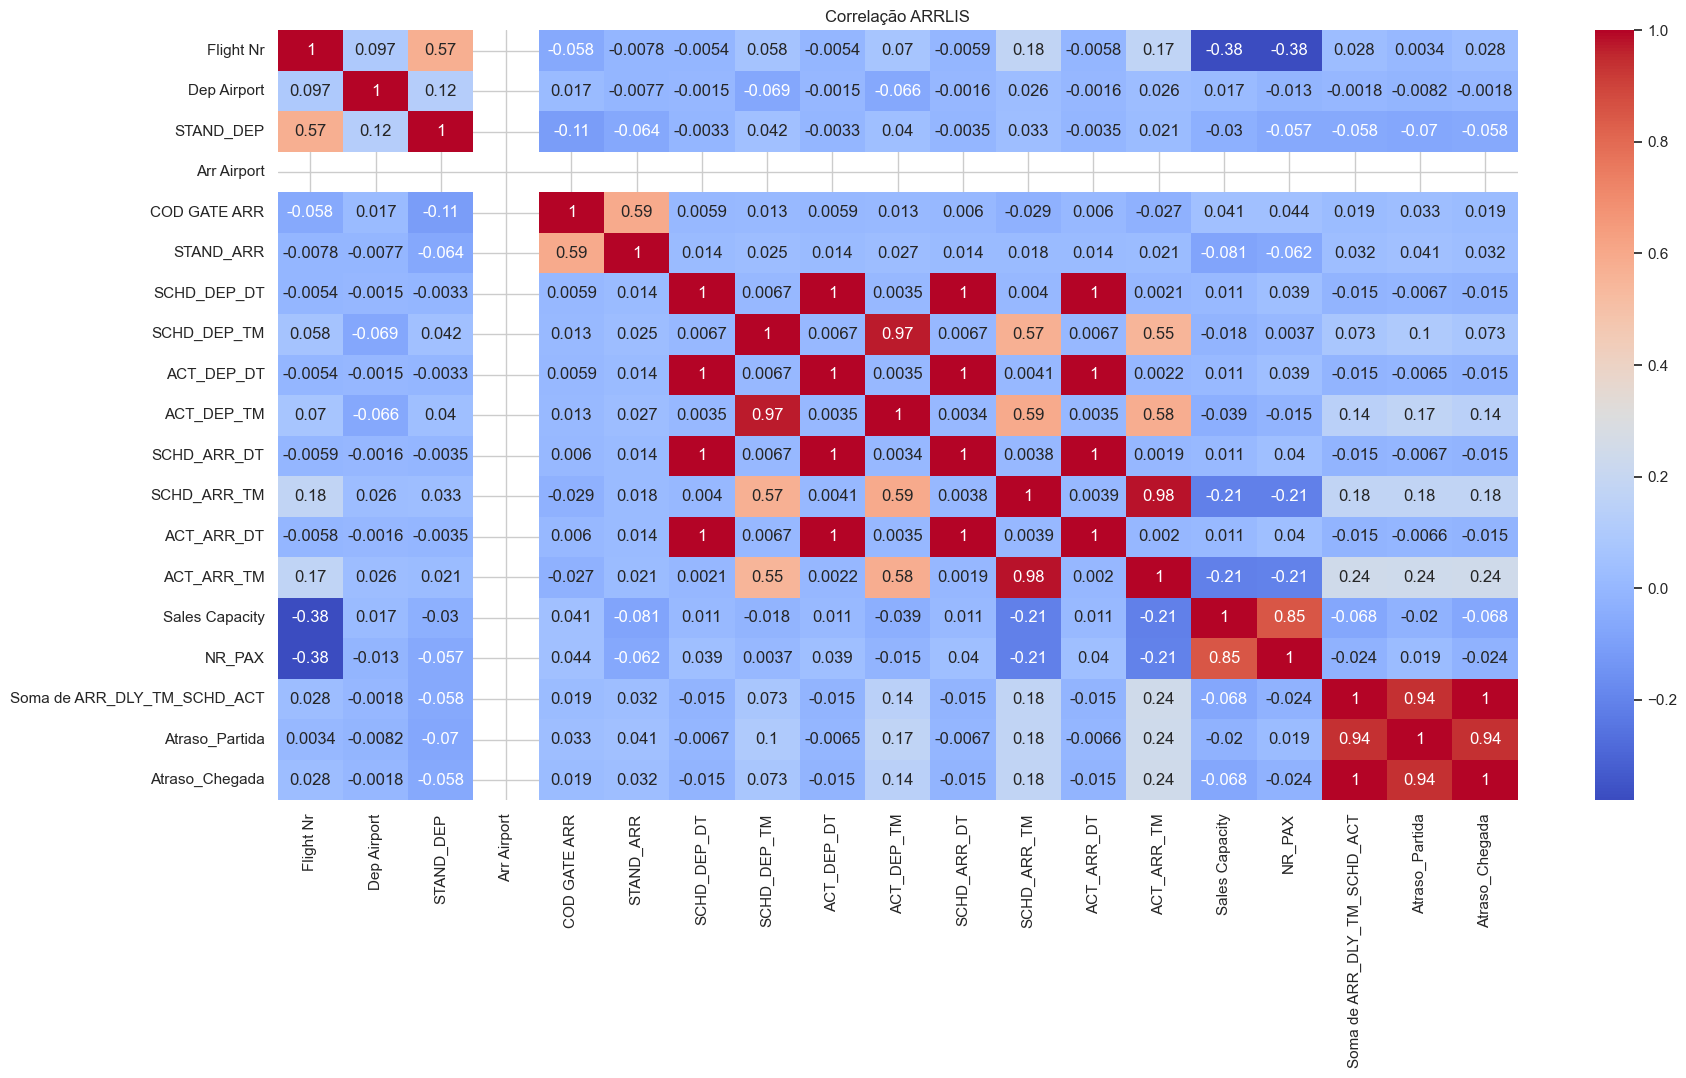

In [6]:
from sklearn.preprocessing import LabelEncoder

df_corr_arr = df_arr.copy()

label_cols = df_corr_arr.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in label_cols:
    try:
        df_corr_arr[col] = le.fit_transform(df_corr_arr[col])
    except:
        df_corr_arr[col] = df_corr_arr[col].astype(str).apply(lambda x: hash(x) % 1000)

plt.figure(figsize=(20, 10))
sns.heatmap(df_corr_arr[:].corr(), annot=True, cmap='coolwarm')
plt.title("Correlação ARRLIS")
plt.show()

In [7]:
# Criar matriz de correlação
corr = df_corr_arr.corr()

# Escolher o target que você quer analisar: "Atraso_Chegada" ou "Atraso_Partida"
target_corr = corr['Atraso_Partida'].abs().sort_values(ascending=False)

# Definir limiar de correlação
threshold = 0.03
selected_features = target_corr[target_corr > threshold].index.tolist()

print(f'Selected {len(selected_features)} features com |corr| > {threshold}:')
print(target_corr[selected_features], "\n")

Selected 10 features com |corr| > 0.03:
Atraso_Partida                 1.000000
Soma de ARR_DLY_TM_SCHD_ACT    0.938752
Atraso_Chegada                 0.938752
ACT_ARR_TM                     0.235167
SCHD_ARR_TM                    0.176808
ACT_DEP_TM                     0.172876
SCHD_DEP_TM                    0.100721
STAND_DEP                      0.070454
STAND_ARR                      0.041253
COD GATE ARR                   0.033098
Name: Atraso_Partida, dtype: float64 



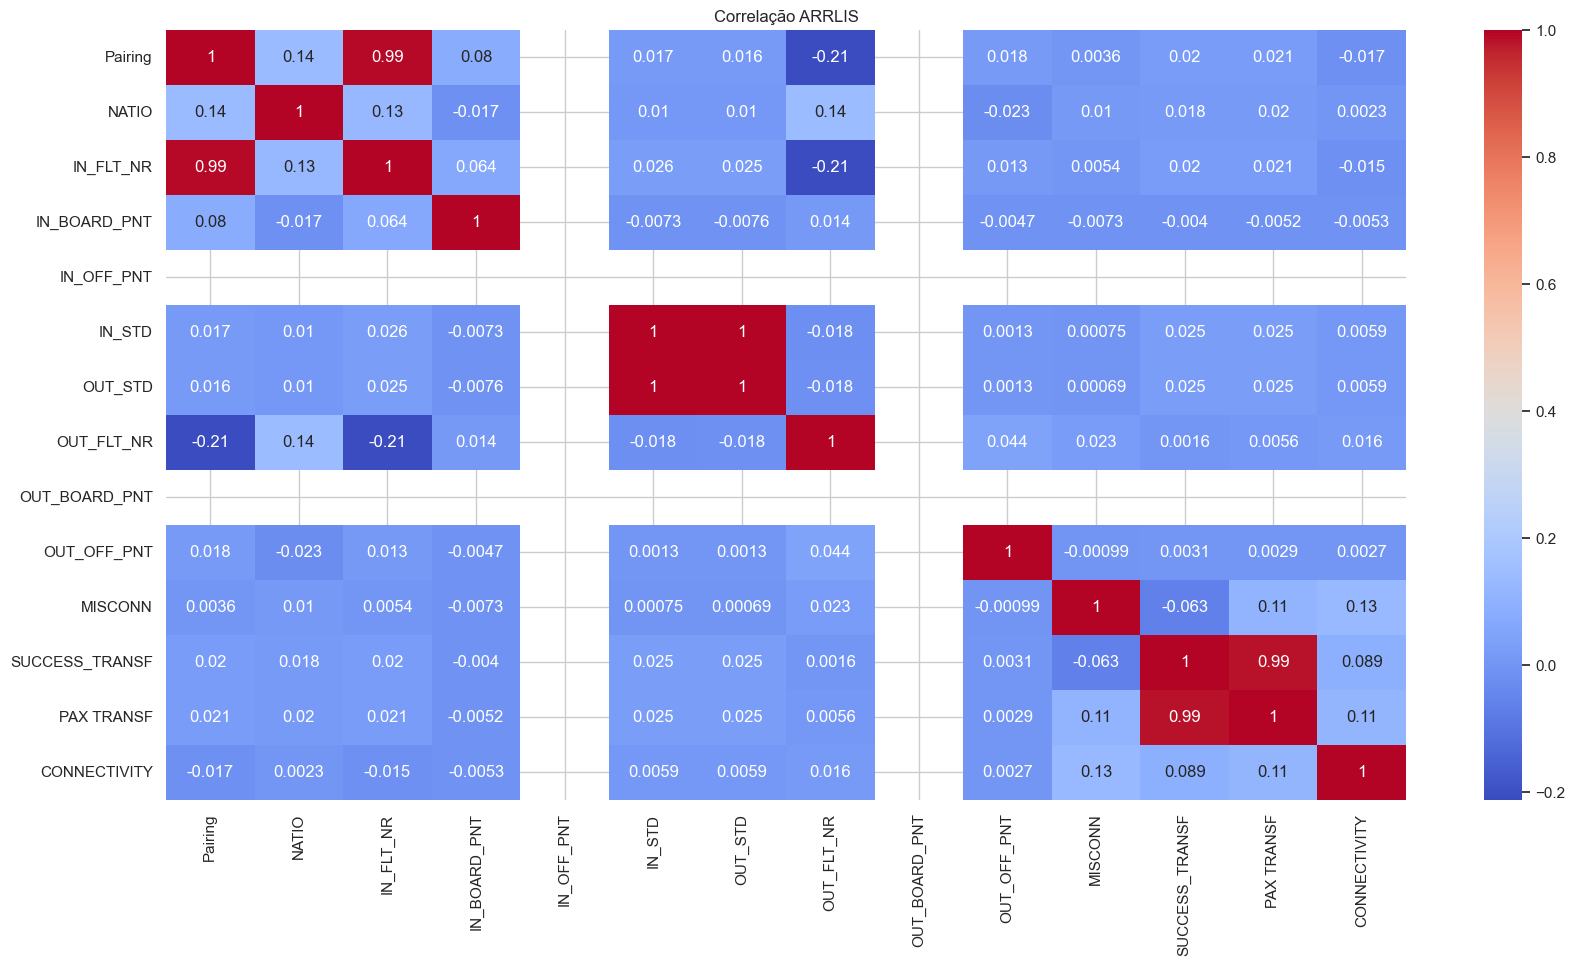

In [8]:
from sklearn.preprocessing import LabelEncoder

df_corr_con = df_con.copy()

label_cols = df_corr_con.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in label_cols:
    try:
        df_corr_con[col] = le.fit_transform(df_corr_con[col])
    except:
        df_corr_con[col] = df_corr_con[col].astype(str).apply(lambda x: hash(x) % 1000)

plt.figure(figsize=(20, 10))
sns.heatmap(df_corr_con[:].corr(), annot=True, cmap='coolwarm')
plt.title("Correlação ARRLIS")
plt.show()

In [9]:
# Criar matriz de correlação
corr = df_corr_con.corr()

# Escolher o target que você quer analisar: "Atraso_Chegada" ou "Atraso_Partida"
target_corr = corr['MISCONN'].abs().sort_values(ascending=False)

# Definir limiar de correlação
threshold = 0.01
selected_features = target_corr[target_corr > threshold].index.tolist()

print(f'Selected {len(selected_features)} features com |corr| > {threshold}:')
print(target_corr[selected_features], "\n")

Selected 6 features com |corr| > 0.01:
MISCONN           1.000000
CONNECTIVITY      0.130536
PAX TRANSF        0.108218
SUCCESS_TRANSF    0.063047
OUT_FLT_NR        0.023113
NATIO             0.010448
Name: MISCONN, dtype: float64 



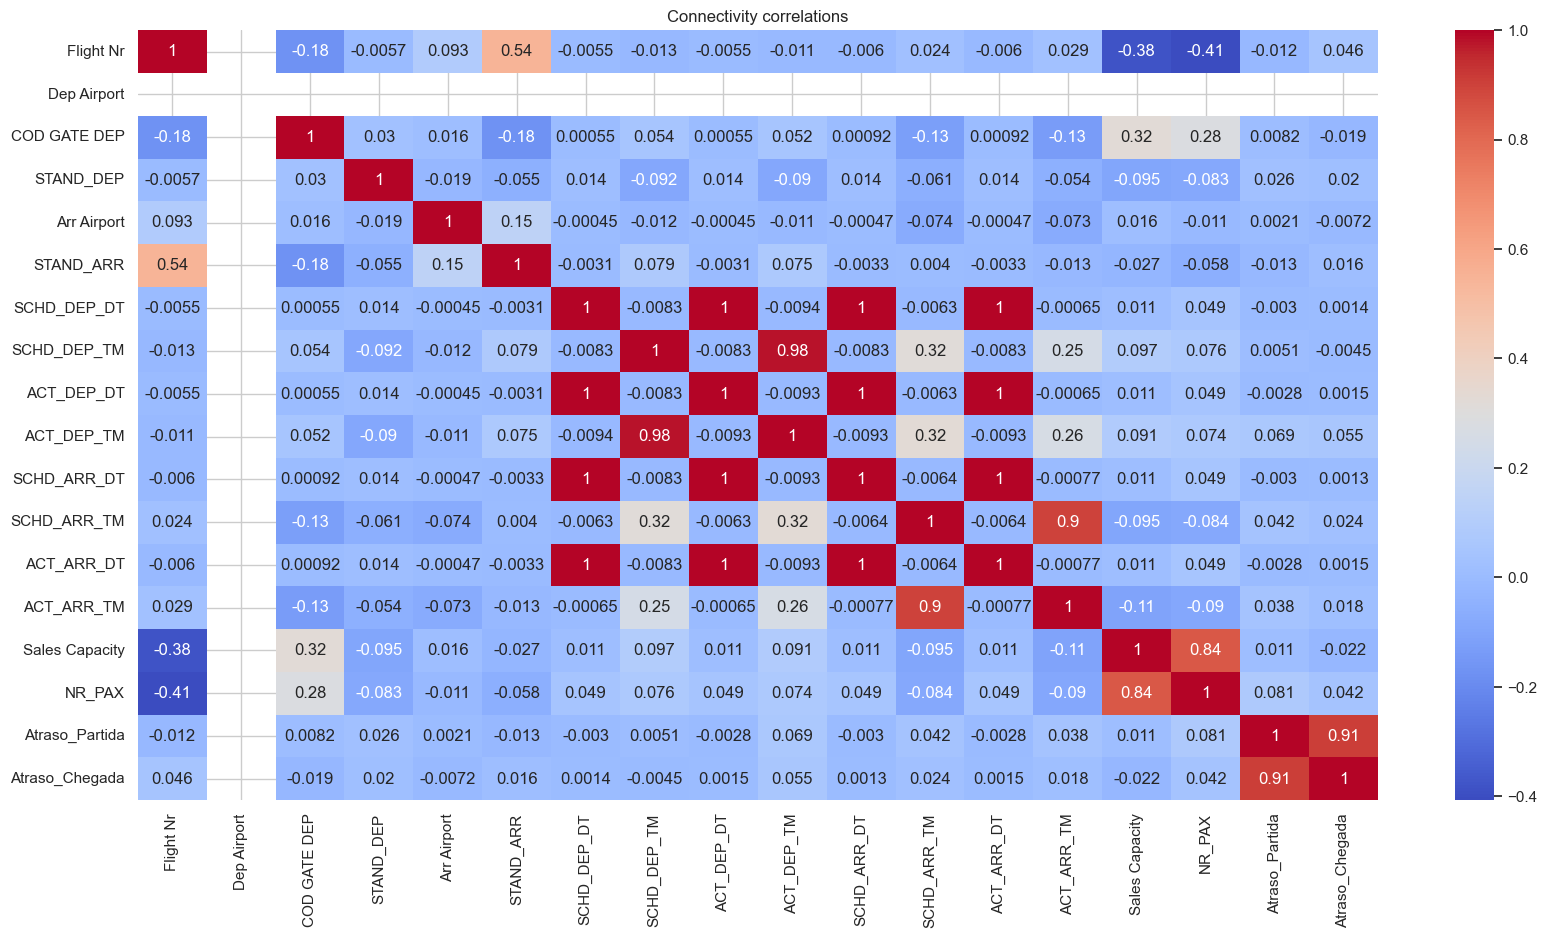

In [10]:
from sklearn.preprocessing import LabelEncoder

df_corr_dep = df_dep.copy()

label_cols = df_corr_dep.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in label_cols:
    try:
        df_corr_dep[col] = le.fit_transform(df_corr_dep[col])
    except:
        df_corr_dep[col] = df_corr_dep[col].astype(str).apply(lambda x: hash(x) % 1000)

plt.figure(figsize=(20, 10))
sns.heatmap(df_corr_dep[:].corr(), annot=True, cmap='coolwarm')
plt.title("Connectivity correlations")
plt.show()

In [11]:
# Criar matriz de correlação
corr = df_corr_dep.corr()

# Escolher o target que você quer analisar: "Atraso_Chegada" ou "Atraso_Partida"
target_corr = corr['Atraso_Partida'].abs().sort_values(ascending=False)

# Definir limiar de correlação
threshold = 0.005
selected_features = target_corr[target_corr > threshold].index.tolist()

print(f'Selected {len(selected_features)} features com |corr| > {threshold}:')
print(target_corr[selected_features], "\n")


Selected 12 features com |corr| > 0.005:
Atraso_Partida    1.000000
Atraso_Chegada    0.910212
NR_PAX            0.080775
ACT_DEP_TM        0.069274
SCHD_ARR_TM       0.042315
ACT_ARR_TM        0.038361
STAND_DEP         0.026057
STAND_ARR         0.013202
Flight Nr         0.012273
Sales Capacity    0.010974
COD GATE DEP      0.008211
SCHD_DEP_TM       0.005100
Name: Atraso_Partida, dtype: float64 



In [12]:
# Função para verificar valores nulos por coluna em qualquer DataFrame
def verificar_nulos(df, nome_df):
    print(f"\nDados omissos em {nome_df}:")
    print(df.isna().sum().sort_values(ascending=False))

# Verificando para os três DataFrames
verificar_nulos(df_arr, "ARRLIS")
verificar_nulos(df_con, "CONNLIS")
verificar_nulos(df_dep, "DEPLIS")



Dados omissos em ARRLIS:
Flight Nr                      0
Dep Airport                    0
STAND_DEP                      0
Arr Airport                    0
COD GATE ARR                   0
STAND_ARR                      0
SCHD_DEP_DT                    0
SCHD_DEP_TM                    0
ACT_DEP_DT                     0
ACT_DEP_TM                     0
SCHD_ARR_DT                    0
SCHD_ARR_TM                    0
ACT_ARR_DT                     0
ACT_ARR_TM                     0
Sales Capacity                 0
NR_PAX                         0
Soma de ARR_DLY_TM_SCHD_ACT    0
Atraso_Partida                 0
Atraso_Chegada                 0
dtype: int64

Dados omissos em CONNLIS:
Pairing           0
NATIO             0
IN_FLT_NR         0
IN_BOARD_PNT      0
IN_OFF_PNT        0
IN_STD            0
OUT_STD           0
OUT_FLT_NR        0
OUT_BOARD_PNT     0
OUT_OFF_PNT       0
MISCONN           0
SUCCESS_TRANSF    0
PAX TRANSF        0
CONNECTIVITY      0
dtype: int64

Dados omissos

preprocess_split_v2.py: Lê os seus ficheiros CSV originais, faz o merge, remove linhas sem correspondência ou com target inválido, exclui features com leakage, calcula métricas de exclusão e divide os dados válidos em dados_processados_treino.csv (80%) e dados_processados_teste.csv (20%).


train_final_smote_v2.py: Lê dados_processados_treino.csv, aplica SMOTE para oversampling, aplica scaling e treina o modelo SGDClassifier (incrementalmente se use_batches=True). Salva final_model_smote.joblib e final_scaler_smote.joblib.


evaluate_final_v2.py: Lê dados_processados_teste.csv, carrega o modelo e scaler treinados, aplica scaling e avalia o desempenho do modelo, com verificações de robustez adicionadas.

Juntar todos os dados fazendo correspondência das colunas Flight Nr dos df_arr e df_dep do tipo exemplo(TP 0288) com a coluna Pairing do tipo exemplo (TP 0232 IAD - LAD TP 0287).

In [37]:
import pandas as pd
import numpy as np
import time
import os
from sklearn.model_selection import train_test_split # Used for the 80/20 split logic

# --- Configuration ---
# File paths (ASSUMES files are in the same directory as the script)
conn_file = "./dados_combinados_CONNECTLIS.csv"
arr_file = "./dados_combinados_ARRLIS.csv"
dep_file = "./dados_combinados_DEPLIS.csv"

# Output files
train_output_file = "./dados_processados_treino.csv"
test_output_file = "./dados_processados_teste.csv"

# Columns to keep (Based on previous user input and keys)
# Ensure key columns and essential columns for checking merge success are included
cols_to_keep_arr = [
    "Flight Nr", "Soma de ARR_DLY_TM_SCHD_ACT", "ACT_ARR_TM", "SCHD_ARR_TM", 
    "ACT_DEP_TM", "SCHD_DEP_TM", "STAND_DEP", "STAND_ARR", "COD GATE ARR"
]
cols_to_keep_con = [
    "IN_FLT_NR", "OUT_FLT_NR", "MISCONN", "CONNECTIVITY", 
    "PAX TRANSF", "SUCCESS_TRANSF"
]
cols_to_keep_dep = [
    "Flight Nr", "NR_PAX", "ACT_DEP_TM", "SCHD_ARR_TM", "ACT_ARR_TM"
]

# Target variable
target_column = "MISCONN"
expected_classes = [0, 1] # Define the valid classes for the target

# Features to EXCLUDE due to data leakage
leakage_features_to_exclude = ["Soma de ARR_DLY_TM_SCHD_ACT", "SUCCESS_TRANSF"]

# Batch processing parameters
batch_size = 200000 # Adjust based on available RAM

# Train/Test Split Ratio
test_size_ratio = 0.20
random_state_split = 42 # For reproducibility of the split

# --- Helper Functions ---
def check_file_exists(filepath):
    if not os.path.exists(filepath):
        print(f"ERRO FATAL: Ficheiro não encontrado: {filepath}")
        return False
    return True

def load_lookup_df(filepath, cols_to_keep, key_col):
    """Loads smaller dataframes fully into memory if possible, selecting columns and setting index."""
    print(f"Tentando carregar ficheiro de lookup: {filepath}")
    if not check_file_exists(filepath):
        return None
    try:
        if key_col not in cols_to_keep:
             cols_to_keep = cols_to_keep + [key_col]
        df = pd.read_csv(filepath, usecols=cols_to_keep, low_memory=False)
        df[key_col] = df[key_col].astype(str).str.strip()
        df = df.drop_duplicates(subset=[key_col], keep='first') 
        df = df.set_index(key_col)
        print(f"  - Carregado com sucesso. Shape: {df.shape}")
        return df
    except Exception as e:
        print(f"  - ERRO ao carregar {filepath}: {e}")
        return None

# --- Main Preprocessing and Split Pipeline ---
def run_preprocess_split():
    start_time = time.time()

    # 1. Check for essential input files
    if not all(check_file_exists(f) for f in [conn_file, arr_file, dep_file]):
        print("\nPipeline não iniciado devido a ficheiros de entrada em falta.")
        return

    # 2. Load smaller lookup tables (ARR and DEP)
    df_arr_lookup = load_lookup_df(arr_file, cols_to_keep_arr, "Flight Nr")
    df_dep_lookup = load_lookup_df(dep_file, cols_to_keep_dep, "Flight Nr")

    if df_arr_lookup is None or df_dep_lookup is None:
        print("ERRO: Falha ao carregar ficheiros ARR ou DEP. Abortando.")
        return
        
    # Identify check columns
    original_check_col_arr = next((col for col in df_arr_lookup.columns if col != "Flight Nr"), None)
    original_check_col_dep = next((col for col in df_dep_lookup.columns if col != "Flight Nr"), None)
    
    if not original_check_col_arr or not original_check_col_dep:
        print("ERRO: Não foi possível identificar colunas de verificação nos dataframes ARR/DEP.")
        return

    # 3. Initialize output files (write header)
    first_write_train = True
    first_write_test = True
    header_written = False
    final_columns_list = [] # To store the final column names for the header

    total_rows_processed = 0
    total_rows_valid = 0
    total_rows_train = 0
    total_rows_test = 0
    total_rows_dropped_merge = 0
    total_rows_dropped_target = 0

    print(f"\nIniciando pré-processamento e divisão (80/20) de {conn_file}...")
    print(f"Tamanho do batch: {batch_size}")
    print(f"Ficheiro de treino: {train_output_file}")
    print(f"Ficheiro de teste: {test_output_file}")

    try:
        # 4. Process CONN file in chunks
        for i, df_con_chunk in enumerate(pd.read_csv(conn_file, usecols=cols_to_keep_con, chunksize=batch_size, low_memory=False)):
            batch_start_time = time.time()
            print(f"\n--- Processando Batch {i+1} --- Shape: {df_con_chunk.shape}")
            rows_in_batch = len(df_con_chunk)
            total_rows_processed += rows_in_batch

            # Prepare keys
            df_con_chunk["IN_FLT_NR"] = df_con_chunk["IN_FLT_NR"].astype(str).str.strip()
            df_con_chunk["OUT_FLT_NR"] = df_con_chunk["OUT_FLT_NR"].astype(str).str.strip()

            # Merge
            df_merged_chunk = df_con_chunk.join(df_arr_lookup, on="IN_FLT_NR", how="left", lsuffix="_con", rsuffix="_arr")
            df_merged_chunk = df_merged_chunk.join(df_dep_lookup, on="OUT_FLT_NR", how="left", lsuffix="_prev", rsuffix="_dep")
            print(f"  - Merge concluído. Shape após merges: {df_merged_chunk.shape}")

            # Drop rows without full match
            check_col_arr_final = f"{original_check_col_arr}_arr" if f"{original_check_col_arr}_arr" in df_merged_chunk.columns else original_check_col_arr
            check_col_dep_final = f"{original_check_col_dep}_dep" if f"{original_check_col_dep}_dep" in df_merged_chunk.columns else original_check_col_dep
            cols_to_check_for_na = []
            if check_col_arr_final in df_merged_chunk.columns: cols_to_check_for_na.append(check_col_arr_final)
            if check_col_dep_final in df_merged_chunk.columns: cols_to_check_for_na.append(check_col_dep_final)
            
            initial_rows_merge = len(df_merged_chunk)
            if cols_to_check_for_na:
                df_merged_chunk = df_merged_chunk.dropna(subset=cols_to_check_for_na)
            rows_after_drop_merge = len(df_merged_chunk)
            rows_dropped_merge_batch = initial_rows_merge - rows_after_drop_merge
            total_rows_dropped_merge += rows_dropped_merge_batch
            print(f"  - Linhas removidas por falta de correspondência no merge: {rows_dropped_merge_batch}")
            
            if df_merged_chunk.empty:
                print("  - AVISO: Batch vazio após remoção de linhas sem correspondência no merge. Ignorando.")
                continue

            # Validate and Filter Target Column
            initial_rows_target = len(df_merged_chunk)
            df_merged_chunk[target_column] = pd.to_numeric(df_merged_chunk[target_column], errors='coerce')
            df_merged_chunk = df_merged_chunk.dropna(subset=[target_column])
            df_merged_chunk = df_merged_chunk[df_merged_chunk[target_column].isin(expected_classes)]
            if not df_merged_chunk.empty:
                 df_merged_chunk[target_column] = df_merged_chunk[target_column].astype(int)
            rows_after_target_filter = len(df_merged_chunk)
            rows_dropped_target_batch = initial_rows_target - rows_after_target_filter
            total_rows_dropped_target += rows_dropped_target_batch
            print(f"  - Linhas removidas por target inválido/NaN: {rows_dropped_target_batch}")
            
            if df_merged_chunk.empty:
                print("  - AVISO: Batch vazio após filtro da coluna target. Ignorando.")
                continue
            total_rows_valid += len(df_merged_chunk)

            # Select final columns (excluding leakage features)
            if not header_written: # Determine final columns only once
                all_cols = df_merged_chunk.columns.tolist()
                final_columns_list = [col for col in all_cols if col not in leakage_features_to_exclude]
                print(f"  - Colunas finais definidas (sem leakage): {final_columns_list}")
            
            if not final_columns_list:
                print("ERRO CRÍTICO: Não foi possível determinar a lista final de colunas. Abortando.")
                return
                
            df_processed_chunk = df_merged_chunk[final_columns_list]

            # 5. Split data into train/test for the current chunk
            if not df_processed_chunk.empty:
                np.random.seed(random_state_split + i) # Seed changes per batch for variation
                is_test = np.random.rand(len(df_processed_chunk)) < test_size_ratio
                
                df_train_chunk = df_processed_chunk[~is_test]
                df_test_chunk = df_processed_chunk[is_test]

                # 6. Append to output files
                # Write header only if it's the very first write operation to either file
                write_header_train = first_write_train and not header_written
                write_header_test = first_write_test and not header_written
                
                if not df_train_chunk.empty:
                    df_train_chunk.to_csv(train_output_file, mode='a', header=write_header_train, index=False)
                    if write_header_train:
                         first_write_train = False
                         header_written = True # Mark header as written
                    total_rows_train += len(df_train_chunk)
                    
                if not df_test_chunk.empty:
                    df_test_chunk.to_csv(test_output_file, mode='a', header=write_header_test, index=False)
                    if write_header_test:
                         first_write_test = False
                         header_written = True # Mark header as written
                    total_rows_test += len(df_test_chunk)

            batch_time = time.time() - batch_start_time
            print(f"  - Batch {i+1} processado e dividido em {batch_time:.2f} segundos.")

    except Exception as e:
        print(f"\nERRO INESPERADO durante o pré-processamento e divisão: {e}")
        import traceback
        traceback.print_exc()
    finally:
        end_time = time.time()
        total_time = end_time - start_time
        print(f"\n--- Pré-processamento e Divisão Concluídos ---")
        print(f"Total de linhas do ficheiro CONN processadas: {total_rows_processed}")
        print(f"Total de linhas removidas por falha no merge: {total_rows_dropped_merge} ({total_rows_dropped_merge/total_rows_processed:.2%} do total processado)")
        print(f"Total de linhas removidas por target inválido/NaN: {total_rows_dropped_target} ({total_rows_dropped_target/total_rows_processed:.2%} do total processado)")
        print(f"Total de linhas válidas (após merge e filtro): {total_rows_valid}")
        print(f"Total de linhas escritas em {train_output_file}: {total_rows_train}")
        print(f"Total de linhas escritas em {test_output_file}: {total_rows_test}")
        print(f"Tempo total de execução: {total_time:.2f} segundos.")

# --- Executar Pipeline ---
if __name__ == "__main__":
    # Remove output files if they exist to start fresh
    if os.path.exists(train_output_file):
        os.remove(train_output_file)
        print(f"Ficheiro de treino anterior removido: {train_output_file}")
    if os.path.exists(test_output_file):
        os.remove(test_output_file)
        print(f"Ficheiro de teste anterior removido: {test_output_file}")
        
    run_preprocess_split()

Ficheiro de treino anterior removido: ./dados_processados_treino.csv
Ficheiro de teste anterior removido: ./dados_processados_teste.csv
Tentando carregar ficheiro de lookup: ./dados_combinados_ARRLIS.csv
  - Carregado com sucesso. Shape: (508, 8)
Tentando carregar ficheiro de lookup: ./dados_combinados_DEPLIS.csv
  - Carregado com sucesso. Shape: (464, 4)

Iniciando pré-processamento e divisão (80/20) de ./dados_combinados_CONNECTLIS.csv...
Tamanho do batch: 200000
Ficheiro de treino: ./dados_processados_treino.csv
Ficheiro de teste: ./dados_processados_teste.csv

--- Processando Batch 1 --- Shape: (200000, 6)
  - Merge concluído. Shape após merges: (200000, 18)
  - Linhas removidas por falta de correspondência no merge: 11368
  - Linhas removidas por target inválido/NaN: 3418
  - Colunas finais definidas (sem leakage): ['IN_FLT_NR', 'OUT_FLT_NR', 'MISCONN', 'PAX TRANSF', 'CONNECTIVITY', 'STAND_DEP', 'COD GATE ARR', 'STAND_ARR', 'SCHD_DEP_TM', 'ACT_DEP_TM_prev', 'SCHD_ARR_TM_prev', 'AC

In [ ]:
## Nota sobre o Merge e Divisão:

# Hipotese: Merge por batches pode escolher batches cujos resgistos não têm correspondencia no merge, mas existir correspondência fora dos batches. (Verificar hipotese)

# Adicionar percentagem de perda de informação após este tratamento

# Adicionar corretamente os labels das colunas aos csv's teste e treino: ['IN_FLT_NR', 'OUT_FLT_NR', 'MISCONN', 'PAX TRANSF', 'CONNECTIVITY', 'STAND_DEP', 'COD GATE ARR', 'STAND_ARR', 'SCHD_DEP_TM', 'ACT_DEP_TM_prev', 'SCHD_ARR_TM_prev', 'ACT_ARR_TM_prev', 'Dep Airport', 'COD GATE DEP', 'ACT_DEP_TM_dep', 'SCHD_ARR_TM_dep', 'ACT_ARR_TM_dep', 'Sales Capacity', 'NR_PAX']
# 
#

## 4. Métodos de Balanceamento + Treino do Modelo

In [39]:
import pandas as pd
import numpy as np
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
# *** MODIFIED: Import SMOTE instead of RandomUnderSampler ***
from imblearn.over_sampling import SMOTE 
import joblib
import time
import os

# --- Configuration ---
# Input file (generated by preprocess_split_v2.py)
train_file = "./dados_processados_treino.csv"

# Target variable
target_column = "MISCONN"

# Model and Scaler files to save
model_file = "./final_model_smote.joblib" # Renamed output file
scaler_file = "./final_scaler_smote.joblib" # Renamed output file

# Batch processing parameters (if train_file is still too large)
use_batches = False # Set to True if dados_processados_treino.csv might exceed memory
batch_size = 500000 # Adjust if using batches

# SMOTE parameters (can be adjusted)
smote_k_neighbors = 5 # Default is 5, adjust if needed based on minority class size

# --- Helper Functions ---
def check_file_exists(filepath):
    if not os.path.exists(filepath):
        print(f"ERRO FATAL: Ficheiro de treino não encontrado: {filepath}")
        return False
    return True

# --- Main Training Pipeline ---
def run_final_training():
    start_time = time.time()

    if not check_file_exists(train_file):
        return

    # Initialize Model, Scaler
    model = SGDClassifier(random_state=42, loss='log_loss') # Using log_loss for probability estimates if needed later
    scaler = StandardScaler()
    # *** MODIFIED: Initialize SMOTE ***
    # Ensure k_neighbors is less than the smallest class count in a batch
    # We might need to adjust k_neighbors dynamically or handle errors if a batch has too few minority samples
    smote = SMOTE(random_state=42, k_neighbors=smote_k_neighbors) 
    
    classes = np.array([0, 1]) # Assuming binary classification
    first_batch = True
    total_rows_processed = 0

    print(f"Iniciando treino final com {train_file}...")
    print(f"Usando SMOTE para oversampling.")

    try:
        if use_batches:
            print(f"Modo Batch Ativado. Tamanho do batch: {batch_size}")
            # Process in chunks if the training file is too large
            for i, df_train_chunk in enumerate(pd.read_csv(train_file, chunksize=batch_size, low_memory=False)):
                batch_start_time = time.time()
                print(f"\n--- Processando Batch de Treino {i+1} --- Shape: {df_train_chunk.shape}")
                total_rows_processed += len(df_train_chunk)

                # Define Features (X) and Target (y)
                numeric_cols = df_train_chunk.select_dtypes(include=np.number).columns.tolist()
                feature_columns = [col for col in numeric_cols if col != target_column]
                
                if not feature_columns:
                    print("  - AVISO: Nenhuma feature numérica (não-target) encontrada no batch. Ignorando.")
                    continue
                    
                X_chunk = df_train_chunk[feature_columns]
                y_chunk = df_train_chunk[target_column]
                print(f"  - Features selecionadas: {feature_columns}")

                # *** MODIFIED: Balanceamento (SMOTE) ***
                print(f"  - Distribuição antes do SMOTE: {y_chunk.value_counts().to_dict()}")
                try:
                    # Check if minority class has enough samples for k_neighbors
                    minority_count = y_chunk.value_counts().min()
                    if y_chunk.nunique() >= 2 and minority_count > 0:
                        # Adjust k_neighbors if it's >= minority_count
                        current_k = min(smote_k_neighbors, minority_count - 1) if minority_count > 1 else 1
                        if current_k != smote.k_neighbors:
                             print(f"    - Ajustando k_neighbors do SMOTE para {current_k} neste batch.")
                             smote_batch = SMOTE(random_state=42, k_neighbors=current_k)
                        else:
                             smote_batch = smote # Use the original smote object
                        
                        if current_k >= 1:
                            X_resampled, y_resampled = smote_batch.fit_resample(X_chunk, y_chunk)
                            print(f"  - Distribuição após SMOTE: {y_resampled.value_counts().to_dict()}")
                        else:
                            print("  - AVISO: Classe minoritária com apenas 1 amostra. SMOTE não aplicável. Usando dados originais.")
                            X_resampled, y_resampled = X_chunk, y_chunk
                    else:
                        print("  - AVISO: SMOTE não aplicável (menos de 2 classes ou classe minoritária vazia).")
                        X_resampled, y_resampled = X_chunk, y_chunk
                except ValueError as ve:
                    print(f"  - AVISO: Erro no SMOTE: {ve}. Usando dados originais do batch.")
                    X_resampled, y_resampled = X_chunk, y_chunk

                if X_resampled.empty:
                    print("  - AVISO: Batch vazio após SMOTE. Ignorando.")
                    continue

                # Scaling
                if first_batch:
                    X_scaled = scaler.fit_transform(X_resampled)
                    print(f"  - Scaler ajustado no primeiro batch.")
                else:
                    try:
                        # Ensure columns are in the order the scaler expects
                        if hasattr(scaler, "feature_names_in_"):
                             X_resampled_ordered = X_resampled[scaler.feature_names_in_]
                        else:
                             X_resampled_ordered = X_resampled # Proceed with caution
                        X_scaled = scaler.transform(X_resampled_ordered)
                        print("  - Batch escalado com scaler pré-ajustado.")
                    except Exception as scale_err:
                        print(f"  - ERRO durante o scaling: {scale_err}. Ignorando batch.")
                        continue

                # Treino Incremental
                if y_resampled.empty:
                    print("  - AVISO: y_resampled vazio antes do treino. Ignorando batch.")
                    continue
                    
                if first_batch:
                    try:
                        model.partial_fit(X_scaled, y_resampled, classes=classes)
                        first_batch = False
                        print("  - Modelo treinado no primeiro batch (com classes).")
                    except ValueError as fit_err:
                        print(f"  - ERRO no primeiro partial_fit: {fit_err}. Ignorando batch.")
                        continue
                else:
                    try:
                        model.partial_fit(X_scaled, y_resampled)
                        print("  - Modelo atualizado com o batch.")
                    except ValueError as fit_err:
                        print(f"  - ERRO no partial_fit subsequente: {fit_err}. Ignorando batch.")
                        continue
                        
                batch_time = time.time() - batch_start_time
                print(f"  - Batch {i+1} concluído em {batch_time:.2f} segundos.")

        else: # Not using batches, process the whole file
            print("Modo Batch Desativado. Lendo ficheiro de treino completo...")
            df_train = pd.read_csv(train_file, low_memory=False)
            total_rows_processed = len(df_train)
            print(f"Ficheiro lido. Shape: {df_train.shape}")

            # Define Features (X) and Target (y)
            numeric_cols = df_train.select_dtypes(include=np.number).columns.tolist()
            feature_columns = [col for col in numeric_cols if col != target_column]
            
            if not feature_columns:
                 print("ERRO: Nenhuma feature numérica (não-target) encontrada. Abortando.")
                 return
                 
            X = df_train[feature_columns]
            y = df_train[target_column]
            print(f"  - Features selecionadas: {feature_columns}")

            # *** MODIFIED: Balanceamento (SMOTE) ***
            print(f"  - Distribuição antes do SMOTE: {y.value_counts().to_dict()}")
            try:
                minority_count = y.value_counts().min()
                if y.nunique() >= 2 and minority_count > 0:
                    current_k = min(smote_k_neighbors, minority_count - 1) if minority_count > 1 else 1
                    if current_k != smote.k_neighbors:
                         print(f"    - Ajustando k_neighbors do SMOTE para {current_k}.")
                         smote_final = SMOTE(random_state=42, k_neighbors=current_k)
                    else:
                         smote_final = smote
                         
                    if current_k >= 1:
                        X_resampled, y_resampled = smote_final.fit_resample(X, y)
                        print(f"  - Distribuição após SMOTE: {y_resampled.value_counts().to_dict()}")
                    else:
                        print("  - AVISO: Classe minoritária com apenas 1 amostra. SMOTE não aplicável. Usando dados originais.")
                        X_resampled, y_resampled = X, y
                else:
                    print("  - AVISO: SMOTE não aplicável (menos de 2 classes ou classe minoritária vazia).")
                    X_resampled, y_resampled = X, y
            except ValueError as ve:
                 print(f"  - AVISO: Erro no SMOTE: {ve}. Usando dados originais.")
                 X_resampled, y_resampled = X, y
                 
            if X_resampled.empty:
                print("ERRO: Nenhum dado restante após SMOTE. Abortando.")
                return

            # Scaling
            print("Ajustando e aplicando scaler...")
            X_scaled = scaler.fit_transform(X_resampled)

            # Treino
            print("Treinando modelo...")
            model.fit(X_scaled, y_resampled)
            first_batch = False # Mark as trained

        # Salvar Modelo e Scaler Finais
        if not first_batch: # Check if any training actually happened
            joblib.dump(model, model_file)
            joblib.dump(scaler, scaler_file)
            print(f"\nModelo final salvo em: {model_file}")
            print(f"Scaler final salvo em: {scaler_file}")
        else:
            print("\nAVISO: Nenhum treino realizado (possivelmente devido a batches vazios ou erros). Modelo/Scaler não foram salvos.")

    except Exception as e:
        print(f"\nERRO INESPERADO durante o treino final: {e}")
        import traceback
        traceback.print_exc()
    finally:
        end_time = time.time()
        total_time = end_time - start_time
        print(f"\n--- Treino Concluído ---")
        print(f"Total de linhas processadas do ficheiro de treino: {total_rows_processed}")
        print(f"Tempo total de execução do treino: {total_time:.2f} segundos.")

# --- Executar Pipeline ---
if __name__ == "__main__":
    run_final_training()

Iniciando treino final com ./dados_processados_treino.csv...
Usando SMOTE para oversampling.
Modo Batch Desativado. Lendo ficheiro de treino completo...
Ficheiro lido. Shape: (1162317, 16)
  - Features selecionadas: ['PAX TRANSF', 'NR_PAX']
  - Distribuição antes do SMOTE: {0: 1144208, 1: 18109}
  - Distribuição após SMOTE: {0: 1144208, 1: 1144208}
Ajustando e aplicando scaler...
Treinando modelo...

Modelo final salvo em: ./final_model_smote.joblib
Scaler final salvo em: ./final_scaler_smote.joblib

--- Treino Concluído ---
Total de linhas processadas do ficheiro de treino: 1162317
Tempo total de execução do treino: 5.03 segundos.


In [ ]:
## **Nota sobre a Tratamento e Modelagem:**

# Undersampling elimina muita % da inteligência dos dados. Encontrar solução de substituição (oversampling)
# 
#

## 5. Avaliação do Modelo

In [41]:
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib
import time
import os

# --- Configuration ---
# Input file (generated by preprocess_split_v2.py)
test_file = "./dados_processados_teste.csv"

# Model and Scaler files to load (saved by train_final_smote_v2.py)
model_file = "./final_model_smote.joblib" # Ensure this matches the training output
scaler_file = "./final_scaler_smote.joblib" # Ensure this matches the training output

# Target variable
target_column = "MISCONN"
expected_classes = [0, 1] # Define the valid classes for the target

# Batch processing parameters (if test_file is too large)
use_batches = False # Set to True if dados_processados_teste.csv might exceed memory
batch_size = 500000 # Adjust if using batches

# --- Helper Functions ---
def check_file_exists(filepath):
    if not os.path.exists(filepath):
        print(f"ERRO FATAL: Ficheiro não encontrado: {filepath}")
        return False
    return True

# --- Main Evaluation Pipeline ---
def run_final_evaluation():
    start_time = time.time()

    # 1. Check for essential files (Model, Scaler, Test Data)
    if not all(check_file_exists(f) for f in [model_file, scaler_file, test_file]):
        print("ERRO: Ficheiros essenciais (modelo, scaler, dados de teste) em falta. Abortando avaliação.")
        return

    # 2. Load Model and Scaler
    try:
        model = joblib.load(model_file)
        scaler = joblib.load(scaler_file)
        print(f"Modelo carregado de: {model_file}")
        print(f"Scaler carregado de: {scaler_file}")
    except Exception as e:
        print(f"ERRO ao carregar modelo ou scaler: {e}. Abortando avaliação.")
        return

    # Lists to store results
    all_y_true = []
    all_y_pred = []
    total_rows_processed = 0

    print(f"Iniciando avaliação final com {test_file}...")

    try:
        if use_batches:
            print(f"Modo Batch Ativado. Tamanho do batch: {batch_size}")
            # Process in chunks if the test file is too large
            for i, df_test_chunk in enumerate(pd.read_csv(test_file, chunksize=batch_size, low_memory=False)):
                batch_start_time = time.time()
                print(f"\n--- Processando Batch de Teste {i+1} --- Shape: {df_test_chunk.shape}")
                total_rows_processed += len(df_test_chunk)

                # *** ADDED: Check if target column exists early ***
                if target_column not in df_test_chunk.columns:
                    print(f"  - ERRO: Coluna target ", target_column, " não encontrada neste batch. Ignorando.")
                    continue
                    
                # *** ADDED: Check if dataframe is empty early ***
                if df_test_chunk.empty:
                    print("  - AVISO: Batch de teste vazio. Ignorando.")
                    continue

                # Define Features (X) and Target (y)
                numeric_cols = df_test_chunk.select_dtypes(include=np.number).columns.tolist()
                feature_columns = [col for col in numeric_cols if col != target_column]
                
                # Check if scaler expects these features
                expected_features = []
                if hasattr(scaler, "feature_names_in_"):
                    expected_features = scaler.feature_names_in_
                    missing_features = set(expected_features) - set(feature_columns)
                    if missing_features:
                        print(f"  - AVISO: Features esperadas pelo scaler em falta no teste: {missing_features}. Adicionando como 0.")
                        for mf in missing_features:
                            df_test_chunk[mf] = 0
                        feature_columns = list(expected_features)
                    else:
                        feature_columns = [col for col in expected_features if col in feature_columns]
                elif not feature_columns:
                    print("  - AVISO: Nenhuma feature numérica válida encontrada e scaler sem feature_names_in_. Ignorando batch.")
                    continue
                else:
                    print(f"  - AVISO: Scaler sem feature_names_in_. Usando features encontradas: {feature_columns}")

                if not feature_columns:
                    print("  - AVISO: Nenhuma feature final encontrada no batch após verificação do scaler. Ignorando.")
                    continue
                    
                X_test_chunk = df_test_chunk[feature_columns]
                # *** ADDED: Check target column again before access ***
                if target_column not in df_test_chunk.columns:
                     print(f"  - ERRO: Coluna target ", target_column, " desapareceu antes da seleção de y. Ignorando batch.")
                     continue
                y_test_chunk = df_test_chunk[target_column]
                print(f"  - Features selecionadas: {feature_columns}")

                # Scaling
                try:
                    X_test_chunk_ordered = X_test_chunk[expected_features] if expected_features else X_test_chunk
                    X_test_scaled = scaler.transform(X_test_chunk_ordered)
                    print("  - Batch de teste escalado.")
                except Exception as scale_err:
                    print(f"  - ERRO durante o scaling do teste: {scale_err}. Ignorando batch.")
                    continue

                # Prediction
                try:
                    y_pred_chunk = model.predict(X_test_scaled)
                    print("  - Previsões realizadas no batch de teste.")
                except Exception as pred_err:
                    print(f"  - ERRO durante a previsão: {pred_err}. Ignorando batch.")
                    continue

                # Accumulate results
                all_y_true.extend(y_test_chunk.tolist())
                all_y_pred.extend(y_pred_chunk.tolist())

                batch_time = time.time() - batch_start_time
                print(f"  - Batch {i+1} concluído em {batch_time:.2f} segundos.")

        else: # Not using batches, process the whole file
            print("Modo Batch Desativado. Lendo ficheiro de teste completo...")
            df_test = pd.read_csv(test_file, low_memory=False)
            total_rows_processed = len(df_test)
            print(f"Ficheiro lido. Shape: {df_test.shape}")

            # *** ADDED: Check if target column exists ***
            if target_column not in df_test.columns:
                print(f"ERRO: Coluna target ", target_column, " não encontrada no ficheiro de teste. Abortando.")
                return
                
            # *** ADDED: Check if dataframe is empty ***
            if df_test.empty:
                print("ERRO: Ficheiro de teste vazio. Abortando.")
                return

            # Define Features (X) and Target (y)
            numeric_cols = df_test.select_dtypes(include=np.number).columns.tolist()
            feature_columns = [col for col in numeric_cols if col != target_column]
            
            # Check if scaler expects these features
            expected_features = []
            if hasattr(scaler, "feature_names_in_"):
                 expected_features = scaler.feature_names_in_
                 missing_features = set(expected_features) - set(feature_columns)
                 if missing_features:
                      print(f"  - AVISO: Features esperadas pelo scaler em falta no teste: {missing_features}. Adicionando como 0.")
                      for mf in missing_features:
                           df_test[mf] = 0
                      feature_columns = list(expected_features)
                 else:
                      feature_columns = [col for col in expected_features if col in feature_columns]
            elif not feature_columns:
                 print("ERRO: Nenhuma feature numérica válida encontrada e scaler sem feature_names_in_. Abortando.")
                 return
            else:
                 print(f"  - AVISO: Scaler sem feature_names_in_. Usando features encontradas: {feature_columns}")

            if not feature_columns:
                 print("ERRO: Nenhuma feature final encontrada após verificação do scaler. Abortando.")
                 return
                 
            X_test = df_test[feature_columns]
            # *** ADDED: Check target column again before access ***
            if target_column not in df_test.columns:
                 print(f"ERRO: Coluna target ", target_column, " desapareceu antes da seleção de y. Abortando.")
                 return
            y_test = df_test[target_column]
            print(f"  - Features selecionadas: {feature_columns}")

            # Scaling
            print("Aplicando scaler...")
            X_test_ordered = X_test[expected_features] if expected_features is not None and len(expected_features) > 0 else X_test
            X_test_scaled = scaler.transform(X_test_ordered)

            # Prediction
            print("Realizando previsões...")
            y_pred = model.predict(X_test_scaled)

            all_y_true = y_test.tolist()
            all_y_pred = y_pred.tolist()

        # Calculate Overall Metrics
        print("\n--- Avaliação Geral Concluída ---")
        if not all_y_true:
            print("AVISO: Nenhum dado foi avaliado. Verifique o ficheiro de teste e o pipeline.")
        else:
            accuracy = accuracy_score(all_y_true, all_y_pred)
            print(f"Total de linhas avaliadas: {len(all_y_true)}")
            print(f"Acurácia Geral: {accuracy:.4f}")
            
            print("\nMatriz de Confusão Geral:")
            cm_labels = sorted(list(set(all_y_true) | set(all_y_pred)))
            # Ensure labels are [0, 1] if possible for standard confusion matrix
            if set(cm_labels).issubset(set(expected_classes)):
                 cm_labels = expected_classes
            print(confusion_matrix(all_y_true, all_y_pred, labels=cm_labels))
            
            print("\nRelatório de Classificação Geral:")
            # Ensure target_names match the labels order
            target_names = [f"Classe {l}" for l in cm_labels]
            print(classification_report(all_y_true, all_y_pred, labels=cm_labels, target_names=target_names, zero_division=0))

    except Exception as e:
        print(f"\nERRO INESPERADO durante a avaliação final: {e}")
        import traceback
        traceback.print_exc()
    finally:
        end_time = time.time()
        total_time = end_time - start_time
        print(f"\n--- Avaliação Concluída ---")
        print(f"Total de linhas processadas do ficheiro de teste: {total_rows_processed}")
        print(f"Tempo total de execução da avaliação: {total_time:.2f} segundos.")

# --- Executar Pipeline de Avaliação ---
if __name__ == "__main__":
    run_final_evaluation()

Modelo carregado de: ./final_model_smote.joblib
Scaler carregado de: ./final_scaler_smote.joblib
Iniciando avaliação final com ./dados_processados_teste.csv...
Modo Batch Desativado. Lendo ficheiro de teste completo...
Ficheiro lido. Shape: (290292, 16)
  - Features selecionadas: ['PAX TRANSF', 'NR_PAX']
Aplicando scaler...
Realizando previsões...

--- Avaliação Geral Concluída ---
Total de linhas avaliadas: 290292
Acurácia Geral: 0.4899

Matriz de Confusão Geral:
[[138918 146865]
 [  1221   3288]]

Relatório de Classificação Geral:
              precision    recall  f1-score   support

    Classe 0       0.99      0.49      0.65    285783
    Classe 1       0.02      0.73      0.04      4509

    accuracy                           0.49    290292
   macro avg       0.51      0.61      0.35    290292
weighted avg       0.98      0.49      0.64    290292


--- Avaliação Concluída ---
Total de linhas processadas do ficheiro de teste: 290292
Tempo total de execução da avaliação: 0.73 segun

ROC

AUC